## Load Data

In [50]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/olympiad_results.csv')
df_dict = pd.read_csv('../data/olympiad_data_dictionary.csv')

print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (8037, 46)


,student_id,region,school_number,grade,start_time,end_time,Task_1_answer,Task_1_correct,Task_1_time_spent,Task_2_answer,...,Task_11_answer,Task_11_correct,Task_11_time_spent,Task_12_answer,Task_12_correct,Task_12_time_spent,total_score,device_type,attempts_count,disconnects
0,S200000,Краснодар,9,11,2026-04-10 11:10:00,2026-04-10 11:25:19,4.0,0.0,93.0,1.0,...,2.0,0.0,84.0,4.0,0.0,124.0,3,desktop,2,0
1,S200001,Ростов-на-Дону,44,9,2026-04-10 10:30:00,2026-04-10 10:44:19,3.0,0.0,105.0,2.0,...,4.0,1.0,73.0,4.0,0.0,63.0,6,mobile,2,0
2,S200002,Екатеринбург,44,9,2026-04-10 10:25:00,2026-04-10 10:38:33,4.0,1.0,60.0,3.0,...,1.0,1.0,101.0,1.0,1.0,77.0,7,mobile,1,1
3,S200003,Казань,44,11,2026-04-10 10:04:00,2026-04-10 10:18:18,1.0,0.0,58.0,1.0,...,4.0,0.0,100.0,3.0,1.0,86.0,5,mobile,1,0
4,S200004,Уфа,26,9,2026-04-10 10:53:00,2026-04-10 11:08:36,4.0,0.0,111.0,1.0,...,4.0,0.0,79.0,2.0,0.0,96.0,6,mobile,2,0


<class 'pandas.DataFrame'>
RangeIndex: 8037 entries, 0 to 8036
Data columns (total 46 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          8037 non-null   str    
 1   region              8037 non-null   str    
 2   school_number       8037 non-null   int64  
 3   grade               8037 non-null   int64  
 4   start_time          8037 non-null   str    
 5   end_time            8037 non-null   str    
 6   Task_1_answer       7719 non-null   float64
 7   Task_1_correct      7719 non-null   float64
 8   Task_1_time_spent   7719 non-null   float64
 9   Task_2_answer       7696 non-null   float64
 10  Task_2_correct      7696 non-null   float64
 11  Task_2_time_spent   7696 non-null   float64
 12  Task_3_answer       7722 non-null   float64
 13  Task_3_correct      7722 non-null   float64
 14  Task_3_time_spent   7722 non-null   float64
 15  Task_4_answer       7727 non-null   float64
 16  Task_4_correct   

In [51]:
df.dtypes

student_id                str
region                    str
school_number           int64
grade                   int64
start_time                str
end_time                  str
Task_1_answer         float64
Task_1_correct        float64
Task_1_time_spent     float64
Task_2_answer         float64
Task_2_correct        float64
Task_2_time_spent     float64
Task_3_answer         float64
Task_3_correct        float64
Task_3_time_spent     float64
Task_4_answer         float64
Task_4_correct        float64
Task_4_time_spent     float64
Task_5_answer         float64
Task_5_correct        float64
Task_5_time_spent     float64
Task_6_answer         float64
Task_6_correct        float64
Task_6_time_spent     float64
Task_7_answer         float64
Task_7_correct        float64
Task_7_time_spent     float64
Task_8_answer         float64
Task_8_correct        float64
Task_8_time_spent     float64
Task_9_answer         float64
Task_9_correct        float64
Task_9_time_spent     float64
Task_10_an

## Changes start time and end_time to date time format

In [52]:
df["start_time"] = pd.to_datetime(df["start_time"])
df["end_time"] = pd.to_datetime(df["end_time"])

In [53]:
print(df[["start_time", "end_time"]].dtypes)

start_time    datetime64[us]
end_time      datetime64[us]
dtype: object


In [54]:
df_clean = df.copy()

## Correct region names

In [55]:
print(df_clean["region"].value_counts(dropna=False))

region
Уфа                847
Краснодар          807
Воронеж            807
Ростов-на-Дону     804
Новосибирск        791
Пермь              766
Екатеринбург       754
Казань             748
Москва             736
Санкт-Петербург    718
г.Казань            39
СПб                 37
казань              34
мск                 31
Санкт Петербург     27
москва              26
спб                 26
г. Москва           20
Moskva              19
Name: count, dtype: int64


In [56]:
region_map = {
    "г. Москва": "Москва",
    "Moskva": "Москва",
    "москва": "Москва",
    "мск": "Москва",
    "г.Казань": "Казань",
    "казань": "Казань",
    "Санкт Петербург":"Санкт-Петербург",
    "спб": "Санкт-Петербург",
    "СПб": "Санкт-Петербург",
    
    # add every other variant here
}

df_clean["region"] = df_clean["region"].str.strip().replace(region_map)

print(df_clean["region"].nunique())
print(df_clean["region"].value_counts(dropna=False))

10
region
Уфа                847
Москва             832
Казань             821
Санкт-Петербург    808
Краснодар          807
Воронеж            807
Ростов-на-Дону     804
Новосибирск        791
Пермь              766
Екатеринбург       754
Name: count, dtype: int64


In [57]:
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    print(col, "-", df_clean[col].nunique(), "unique values")
    print(df_clean[col].value_counts(ascending=True).head(10))
    print()

student_id - 8000 unique values
student_id
S200000    1
S200001    1
S200002    1
S200003    1
S200004    1
S200005    1
S200006    1
S200007    1
S200008    1
S200009    1
Name: count, dtype: int64

region - 10 unique values
region
Екатеринбург       754
Пермь              766
Новосибирск        791
Ростов-на-Дону     804
Краснодар          807
Воронеж            807
Санкт-Петербург    808
Казань             821
Москва             832
Уфа                847
Name: count, dtype: int64

device_type - 3 unique values
device_type
tablet      410
mobile     2854
desktop    4773
Name: count, dtype: int64



## Check for duplicates

In [58]:
print("Rows:", len(df_clean))
print("Unique students:", df_clean["student_id"].nunique())

Rows: 8037
Unique students: 8000


In [59]:
print(df_clean["student_id"].value_counts().value_counts())

count
1    7963
2      37
Name: count, dtype: int64


In [60]:
print(df_clean.duplicated().sum())

37


In [61]:
print(df_clean.duplicated(subset=["student_id"]).sum())

37


In [62]:
repeated = df_clean[df_clean.duplicated(subset=["student_id"], keep=False)]
display(repeated.sort_values("student_id").head(10))

,student_id,region,school_number,grade,start_time,end_time,Task_1_answer,Task_1_correct,Task_1_time_spent,Task_2_answer,...,Task_11_answer,Task_11_correct,Task_11_time_spent,Task_12_answer,Task_12_correct,Task_12_time_spent,total_score,device_type,attempts_count,disconnects
234,S200234,Санкт-Петербург,35,9,2026-04-10 10:41:00,2026-04-10 10:55:19,2.0,0.0,55.0,3.0,...,4.0,0.0,68.0,1.0,1.0,75.0,3,mobile,1,0
235,S200234,Санкт-Петербург,35,9,2026-04-10 10:41:00,2026-04-10 10:55:19,2.0,0.0,55.0,3.0,...,4.0,0.0,68.0,1.0,1.0,75.0,3,mobile,1,0
641,S200640,Пермь,48,11,2026-04-10 10:37:00,2026-04-10 10:54:46,2.0,0.0,49.0,4.0,...,2.0,1.0,104.0,2.0,1.0,55.0,7,desktop,1,0
642,S200640,Пермь,48,11,2026-04-10 10:37:00,2026-04-10 10:54:46,2.0,0.0,49.0,4.0,...,2.0,1.0,104.0,2.0,1.0,55.0,7,desktop,1,0
963,S200961,Санкт-Петербург,27,7,2026-04-10 09:25:00,2026-04-10 09:40:14,3.0,1.0,106.0,1.0,...,1.0,1.0,103.0,3.0,0.0,43.0,5,desktop,1,0
964,S200961,Санкт-Петербург,27,7,2026-04-10 09:25:00,2026-04-10 09:40:14,3.0,1.0,106.0,1.0,...,1.0,1.0,103.0,3.0,0.0,43.0,5,desktop,1,0
1029,S201026,Екатеринбург,3,6,2026-04-10 09:21:00,2026-04-10 09:33:28,2.0,1.0,9.0,4.0,...,3.0,0.0,64.0,4.0,1.0,109.0,7,desktop,1,0
1030,S201026,Екатеринбург,3,6,2026-04-10 09:21:00,2026-04-10 09:33:28,2.0,1.0,9.0,4.0,...,3.0,0.0,64.0,4.0,1.0,109.0,7,desktop,1,0
1072,S201067,Уфа,45,10,2026-04-10 11:43:00,2026-04-10 11:56:41,4.0,0.0,41.0,3.0,...,2.0,1.0,46.0,3.0,0.0,58.0,5,tablet,2,0
1071,S201067,Уфа,45,10,2026-04-10 11:43:00,2026-04-10 11:56:41,4.0,0.0,41.0,3.0,...,2.0,1.0,46.0,3.0,0.0,58.0,5,tablet,2,0


- **37 duplicates** have been found we removed duplicates and keeping only the first one

In [63]:
df_clean = df_clean.drop_duplicates(subset=["student_id"], keep="first")

In [64]:
print(len(df_clean), df_clean["student_id"].nunique())

8000 8000


## Check for Unusal values 

In [65]:
text_cols = ["student_id", "region", "device_type"]
for col in text_cols:
    has_spaces = df_clean[col].str.contains(r"^\s|\s$|\s{2,}", na=False)
    different_case = df_clean[col].nunique() - df_clean[col].str.lower().nunique()
    print(col, "- extra spaces:", has_spaces.sum(), "- case variants:", different_case)

student_id - extra spaces: 0 - case variants: 0
region - extra spaces: 0 - case variants: 0
device_type - extra spaces: 0 - case variants: 0


In [66]:
print(df_clean["school_number"].describe())
print(df_clean.groupby("region")["school_number"].nunique())
print(df_clean.groupby(["region", "school_number"]).size().sort_values().head(10))

count    8000.000000
mean       29.999500
std        17.187421
min         1.000000
25%        15.000000
50%        30.000000
75%        45.000000
max        59.000000
Name: school_number, dtype: float64
region
Воронеж            59
Екатеринбург       59
Казань             59
Краснодар          59
Москва             59
Новосибирск        59
Пермь              59
Ростов-на-Дону     59
Санкт-Петербург    59
Уфа                59
Name: school_number, dtype: int64
region           school_number
Екатеринбург     57               4
Воронеж          33               5
                 47               6
                 26               6
Екатеринбург     16               6
Краснодар        17               6
                 26               6
Пермь            1                6
Новосибирск      28               6
Санкт-Петербург  20               7
dtype: int64


In [67]:
print(df_clean["grade"].value_counts().sort_index())
print(df_clean["device_type"].value_counts(dropna=False))
print(df_clean[["total_score", "attempts_count", "disconnects"]].describe())
print(pd.unique(df_clean.filter(like="_correct").values.ravel()))
print(df_clean.filter(like="_answer").stack().value_counts())
print(df_clean.filter(like="_time_spent").stack().describe())

grade
5     1105
6     1173
7     1170
8     1110
9     1131
10    1165
11    1146
Name: count, dtype: int64
device_type
desktop    4752
mobile     2840
tablet      408
Name: count, dtype: int64
       total_score  attempts_count  disconnects
count  8000.000000     8000.000000  8000.000000
mean      5.522250        1.489875     0.192625
std       2.785179        0.499929     0.441639
min       0.000000        1.000000     0.000000
25%       3.000000        1.000000     0.000000
50%       5.000000        1.000000     0.000000
75%       8.000000        2.000000     0.000000
max      12.000000        2.000000     4.000000
[ 0.  1. nan]
3.0    23150
4.0    23148
1.0    23045
2.0    22902
Name: count, dtype: int64
count    92245.000000
mean        72.837455
std         26.325651
min          1.000000
25%         56.000000
50%         73.000000
75%         91.000000
max        191.000000
dtype: float64


In [68]:
# Does total_score match the task results?
df_clean["calculated_score"] = df_clean.filter(like="_correct").sum(axis=1)
print("Score mismatches:", (df_clean["calculated_score"] != df_clean["total_score"]).sum())

Score mismatches: 0


- **the total score** was correctly calculated

In [69]:
# Are session durations sensible?
df_clean["duration_min"] = (df_clean["end_time"] - df_clean["start_time"]).dt.total_seconds() / 60
print(df_clean["duration_min"].describe())
print("Zero or negative durations:", (df_clean["duration_min"] <= 0).sum())

# How many answers took under 5 seconds?
print("Answers under 5 sec:", (df_clean.filter(like="_time_spent") < 5).sum().sum())

count    8000.000000
mean       13.997690
std         2.080260
min         0.300000
25%        13.000000
50%        14.133333
75%        15.216667
max        19.566667
Name: duration_min, dtype: float64
Zero or negative durations: 0
Answers under 5 sec: 864


In [70]:
# How are session durations spread?
bins = [0, 1, 2, 3, 5, 8, 10, 13, 20]
print(pd.cut(df_clean["duration_min"], bins=bins).value_counts().sort_index())

# How many answers under 5 seconds does each student have?
fast_answers = (df_clean.filter(like="_time_spent") < 5).sum(axis=1)
print(fast_answers.value_counts().sort_index())

# What do the shortest sessions look like?
columns = ["student_id", "region", "school_number", "duration_min", "total_score", "attempts_count", "disconnects"]
display(df_clean.sort_values("duration_min")[columns].head(20))

duration_min
(0, 1]        72
(1, 2]         0
(2, 3]         0
(3, 5]         0
(5, 8]         3
(8, 10]       51
(10, 13]    1898
(13, 20]    5976
Name: count, dtype: int64
0     7928
12      72
Name: count, dtype: int64


,student_id,region,school_number,duration_min,total_score,attempts_count,disconnects
2341,S202329,Новосибирск,4,0.300000,1,1,0
2692,S202678,Пермь,37,0.316667,3,1,0
1158,S201152,Новосибирск,25,0.316667,5,1,0
1449,S201441,Воронеж,20,0.333333,4,1,0
648,S200646,Краснодар,59,0.333333,2,1,1
1595,S201586,Казань,31,0.333333,4,1,0
483,S200482,Казань,14,0.333333,3,1,0
3289,S203269,Новосибирск,25,0.350000,3,1,0
2411,S202399,Ростов-на-Дону,55,0.350000,3,1,0
2671,S202657,Воронеж,30,0.350000,2,1,0


In [71]:
df_clean["is_fast"] = df_clean["duration_min"] < 1
print("Fast sessions:", df_clean["is_fast"].sum())

# Compare scores
print(df_clean.groupby("is_fast")["total_score"].describe())

# See who they are
fast = df_clean[df_clean["is_fast"]]
print(fast["region"].value_counts())
print(fast["device_type"].value_counts())
print(fast["grade"].value_counts().sort_index())
print(fast["student_id"].head(10).tolist())

Fast sessions: 72
          count      mean       std  min  25%  50%   75%   max
is_fast                                                       
False    7928.0  5.547175  2.781573  0.0  3.0  6.0  8.00  12.0
True       72.0  2.777778  1.549395  0.0  2.0  3.0  3.25   8.0
region
Воронеж            11
Казань             10
Новосибирск         9
Ростов-на-Дону      9
Пермь               6
Москва              6
Екатеринбург        6
Санкт-Петербург     5
Краснодар           5
Уфа                 5
Name: count, dtype: int64
device_type
desktop    42
mobile     27
tablet      3
Name: count, dtype: int64
grade
5     12
6     13
7     14
8      5
9     12
10     9
11     7
Name: count, dtype: int64
['S200074', 'S200359', 'S200464', 'S200482', 'S200502', 'S200646', 'S200729', 'S200764', 'S200896', 'S200970']


- **Removed 72 sessions (0.9%)** lasting under 1 minute. All 12 answers in each session took under 5 seconds, and the average score (2.78 out of 12) was close to the 3 expected from random guessing.

In [72]:
df_valid = df_clean[~df_clean["is_fast"]].copy()
print(len(df_valid))

7928


In [73]:
school_stats = (
      df_valid.groupby(["region", "school_number"])["total_score"]
      .agg(students="count", mean_score="mean")
      .reset_index()
  )

eligible_schools = school_stats[school_stats["students"] >= 10]
print(len(eligible_schools), "of", len(school_stats), "schools remain")
print(eligible_schools.groupby("region").size())

502 of 590 schools remain
region
Воронеж            49
Екатеринбург       48
Казань             53
Краснодар          49
Москва             51
Новосибирск        47
Пермь              49
Ростов-на-Дону     52
Санкт-Петербург    53
Уфа                51
dtype: int64


In [74]:
top_schools = (
    eligible_schools[eligible_schools["region"] == "Москва"]
    .sort_values("mean_score", ascending=False)
    .head(5)
)
display(top_schools)

,region,school_number,students,mean_score
261,Москва,26,10,7.500000
239,Москва,4,14,7.357143
278,Москва,43,12,6.833333
269,Москва,34,19,6.789474
263,Москва,28,16,6.750000


In [75]:
eligible_schools["region"].unique()

<StringArray>
[        'Воронеж',    'Екатеринбург',          'Казань',       'Краснодар',
          'Москва',     'Новосибирск',           'Пермь',  'Ростов-на-Дону',
 'Санкт-Петербург',             'Уфа']
Length: 10, dtype: str

In [76]:
def get_top_schools(region, n=5):
    region_schools = eligible_schools[eligible_schools["region"] == region]
    return region_schools.sort_values("mean_score", ascending=False).head(n)

for region in sorted(eligible_schools["region"].unique()):
    display(get_top_schools(region))

,region,school_number,students,mean_score
45,Воронеж,46,10,7.100000
52,Воронеж,53,12,6.666667
39,Воронеж,40,17,6.588235
26,Воронеж,27,12,6.500000
31,Воронеж,32,17,6.470588


,region,school_number,students,mean_score
80,Екатеринбург,22,10,7.100000
93,Екатеринбург,35,11,7.090909
105,Екатеринбург,47,18,6.611111
89,Екатеринбург,31,16,6.562500
84,Екатеринбург,26,10,6.500000


,region,school_number,students,mean_score
122,Казань,5,21,7.285714
141,Казань,24,12,6.916667
128,Казань,11,10,6.800000
147,Казань,30,13,6.769231
126,Казань,9,15,6.733333


,region,school_number,students,mean_score
229,Краснодар,53,12,7.166667
189,Краснодар,13,18,6.833333
182,Краснодар,6,17,6.764706
188,Краснодар,12,13,6.538462
225,Краснодар,49,15,6.466667


,region,school_number,students,mean_score
261,Москва,26,10,7.500000
239,Москва,4,14,7.357143
278,Москва,43,12,6.833333
269,Москва,34,19,6.789474
263,Москва,28,16,6.750000


,region,school_number,students,mean_score
346,Новосибирск,52,10,7.500000
300,Новосибирск,6,12,7.250000
351,Новосибирск,57,12,7.166667
333,Новосибирск,39,17,7.117647
343,Новосибирск,49,12,6.666667


,region,school_number,students,mean_score
401,Пермь,48,14,7.285714
381,Пермь,28,11,6.909091
390,Пермь,37,10,6.700000
402,Пермь,49,12,6.666667
387,Пермь,34,17,6.411765


,region,school_number,students,mean_score
425,Ростов-на-Дону,13,20,7.950000
416,Ростов-на-Дону,4,13,7.769231
457,Ростов-на-Дону,45,14,7.142857
449,Ростов-на-Дону,37,15,6.733333
434,Ростов-на-Дону,22,15,6.600000


,region,school_number,students,mean_score
482,Санкт-Петербург,11,12,7.916667
527,Санкт-Петербург,56,10,7.400000
511,Санкт-Петербург,40,21,7.190476
484,Санкт-Петербург,13,11,6.727273
522,Санкт-Петербург,51,12,6.666667


,region,school_number,students,mean_score
587,Уфа,57,11,7.000000
582,Уфа,52,15,6.866667
583,Уфа,53,16,6.562500
562,Уфа,32,15,6.533333
559,Уфа,29,12,6.500000


In [77]:
df_valid = df_valid.drop(columns=["calculated_score", "is_fast"])

In [78]:
df_valid.columns

Index(['student_id', 'region', 'school_number', 'grade', 'start_time',
       'end_time', 'Task_1_answer', 'Task_1_correct', 'Task_1_time_spent',
       'Task_2_answer', 'Task_2_correct', 'Task_2_time_spent', 'Task_3_answer',
       'Task_3_correct', 'Task_3_time_spent', 'Task_4_answer',
       'Task_4_correct', 'Task_4_time_spent', 'Task_5_answer',
       'Task_5_correct', 'Task_5_time_spent', 'Task_6_answer',
       'Task_6_correct', 'Task_6_time_spent', 'Task_7_answer',
       'Task_7_correct', 'Task_7_time_spent', 'Task_8_answer',
       'Task_8_correct', 'Task_8_time_spent', 'Task_9_answer',
       'Task_9_correct', 'Task_9_time_spent', 'Task_10_answer',
       'Task_10_correct', 'Task_10_time_spent', 'Task_11_answer',
       'Task_11_correct', 'Task_11_time_spent', 'Task_12_answer',
       'Task_12_correct', 'Task_12_time_spent', 'total_score', 'device_type',
       'attempts_count', 'disconnects', 'duration_min'],
      dtype='str')

In [79]:
df_valid['Task_11_answer'].value_counts()

Task_11_answer
1.0    1977
4.0    1934
3.0    1911
2.0    1820
Name: count, dtype: int64

In [80]:
df_valid.to_csv("../data/olympiad_results_clean.csv", index=False, encoding="utf-8-sig")

In [81]:
answer_cols = df_valid.filter(like="_answer")
print(answer_cols.notna().sum())
df_valid['tasks_answered'] = answer_cols.notnull().sum(axis=1)
print(df_valid["tasks_answered"].value_counts().sort_index())

Task_1_answer     7610
Task_2_answer     7588
Task_3_answer     7614
Task_4_answer     7621
Task_5_answer     7630
Task_6_answer     7602
Task_7_answer     7619
Task_8_answer     7612
Task_9_answer     7619
Task_10_answer    7613
Task_11_answer    7642
Task_12_answer    7611
dtype: int64
tasks_answered
8        9
9       57
10     566
11    2416
12    4880
Name: count, dtype: int64


## Solve rate and average time

In [82]:
correct = df_valid.filter(regex=r"^Task_\d+_correct$")
correct_ans_per_task = correct.mean(axis=0) * 100
print(correct_ans_per_task.round(1).sort_values())

Task_1_correct     29.8
Task_9_correct     32.0
Task_3_correct     33.9
Task_2_correct     37.8
Task_6_correct     45.1
Task_11_correct    46.7
Task_10_correct    53.3
Task_12_correct    57.2
Task_7_correct     58.7
Task_4_correct     59.2
Task_8_correct     59.8
Task_5_correct     63.9
dtype: float64


In [83]:
avg_time_spent = df_valid.filter(like="_time_spent").mean(axis=0)
avg_time_spent

Task_1_time_spent     64.131537
Task_2_time_spent     69.141276
Task_3_time_spent     66.047675
Task_4_time_spent     78.790185
Task_5_time_spent     81.231062
Task_6_time_spent     71.712839
Task_7_time_spent     79.066938
Task_8_time_spent     79.546374
Task_9_time_spent     65.901037
Task_10_time_spent    75.878760
Task_11_time_spent    72.754122
Task_12_time_spent    77.847983
dtype: float64

# The correct answer precentage per grade for each Task

In [84]:
correct_cols = df_valid.filter(regex=r"^Task_\d+_correct$")
grade_task = correct_cols.groupby(df_valid["grade"]).mean() * 100

display(grade_task.round(0))

,Task_1_correct,Task_2_correct,Task_3_correct,Task_4_correct,Task_5_correct,Task_6_correct,Task_7_correct,Task_8_correct,Task_9_correct,Task_10_correct,Task_11_correct,Task_12_correct
grade,,,,,,,,,,,,
5,22.0,31.0,26.0,49.0,53.0,38.0,47.0,50.0,23.0,44.0,38.0,48.0
6,24.0,32.0,28.0,53.0,57.0,39.0,53.0,54.0,26.0,48.0,41.0,49.0
7,28.0,34.0,32.0,57.0,62.0,43.0,56.0,56.0,29.0,52.0,42.0,55.0
8,27.0,37.0,33.0,60.0,64.0,43.0,58.0,61.0,31.0,50.0,47.0,57.0
9,32.0,40.0,35.0,62.0,68.0,48.0,63.0,64.0,35.0,56.0,52.0,60.0
10,37.0,42.0,39.0,63.0,70.0,49.0,66.0,66.0,38.0,60.0,51.0,64.0
11,38.0,47.0,44.0,70.0,73.0,55.0,67.0,68.0,41.0,62.0,56.0,67.0


# Task difficulty

- **Share of students who left tasks blank**

In [85]:
df_valid.columns

Index(['student_id', 'region', 'school_number', 'grade', 'start_time',
       'end_time', 'Task_1_answer', 'Task_1_correct', 'Task_1_time_spent',
       'Task_2_answer', 'Task_2_correct', 'Task_2_time_spent', 'Task_3_answer',
       'Task_3_correct', 'Task_3_time_spent', 'Task_4_answer',
       'Task_4_correct', 'Task_4_time_spent', 'Task_5_answer',
       'Task_5_correct', 'Task_5_time_spent', 'Task_6_answer',
       'Task_6_correct', 'Task_6_time_spent', 'Task_7_answer',
       'Task_7_correct', 'Task_7_time_spent', 'Task_8_answer',
       'Task_8_correct', 'Task_8_time_spent', 'Task_9_answer',
       'Task_9_correct', 'Task_9_time_spent', 'Task_10_answer',
       'Task_10_correct', 'Task_10_time_spent', 'Task_11_answer',
       'Task_11_correct', 'Task_11_time_spent', 'Task_12_answer',
       'Task_12_correct', 'Task_12_time_spent', 'total_score', 'device_type',
       'attempts_count', 'disconnects', 'duration_min', 'tasks_answered'],
      dtype='str')

In [86]:
skip_rate = df_valid.filter(regex=r"^Task_\d+_answer$").isna().mean(axis=0) * 100
skip_rate.sort_values().round(1)

Task_11_answer    3.6
Task_5_answer     3.8
Task_4_answer     3.9
Task_7_answer     3.9
Task_9_answer     3.9
Task_3_answer     4.0
Task_10_answer    4.0
Task_8_answer     4.0
Task_12_answer    4.0
Task_1_answer     4.0
Task_6_answer     4.1
Task_2_answer     4.3
dtype: float64

In [87]:
task_stats = pd.DataFrame({
    "task": range(1, 13),
    "solve_rate": correct_ans_per_task.values,
    "avg_time_sec": avg_time_spent.values,
    "skip_rate": skip_rate,
})

display(task_stats.sort_values("solve_rate").round(1))

,task,solve_rate,avg_time_sec,skip_rate
Task_1_answer,1,29.8,64.1,4.0
Task_9_answer,9,32.0,65.9,3.9
Task_3_answer,3,33.9,66.0,4.0
Task_2_answer,2,37.8,69.1,4.3
Task_6_answer,6,45.1,71.7,4.1
Task_11_answer,11,46.7,72.8,3.6
Task_10_answer,10,53.3,75.9,4.0
Task_12_answer,12,57.2,77.8,4.0
Task_7_answer,7,58.7,79.1,3.9
Task_4_answer,4,59.2,78.8,3.9


- **Task5** took the longest time with mean 81 seconds, however it was the **easiest task** about ~64% of students who answered got it correct.
- **Task1** had the shortest mean time at 64 seconds, but it was the most **difficult task** only about 30% of students who answered got it right.
- **Skip rate** was almost **similar** for all tasks, so students weren’t noticeably skipping the hardest tasks

In [88]:
print(task_stats["solve_rate"].corr(task_stats["avg_time_sec"]))

0.9984275175192832


In [89]:
# import importlib
# importlib.reload(plt)

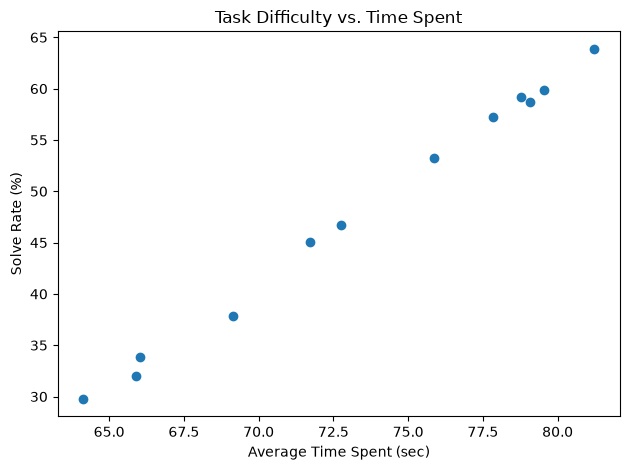

In [90]:
plt.figure(facecolor="white")
plt.scatter(task_stats["avg_time_sec"], task_stats["solve_rate"])
plt.xlabel("Average Time Spent (sec)")
plt.ylabel("Solve Rate (%)")
plt.title("Task Difficulty vs. Time Spent")
plt.tight_layout()
plt.show()

- There is 99% correlation between the correct answers rate and average time taken to answer each of the questions, as time to answer increase the probability to have a correct answer is higher, the relation is linear

grade
5     1093
6     1160
7     1156
8     1105
9     1119
10    1156
11    1139
Name: count, dtype: int64


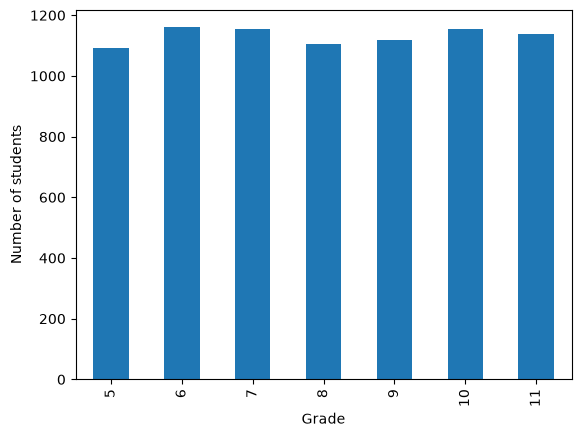

In [91]:
grade_counts = df_valid["grade"].value_counts().sort_index()
print(grade_counts)

grade_counts.plot(kind="bar")
plt.xlabel("Grade")
plt.ylabel("Number of students")
plt.show()

region
Уфа                838
Москва             824
Казань             811
Краснодар          801
Санкт-Петербург    796
Воронеж            792
Ростов-на-Дону     787
Новосибирск        777
Пермь              757
Екатеринбург       745
Name: count, dtype: int64


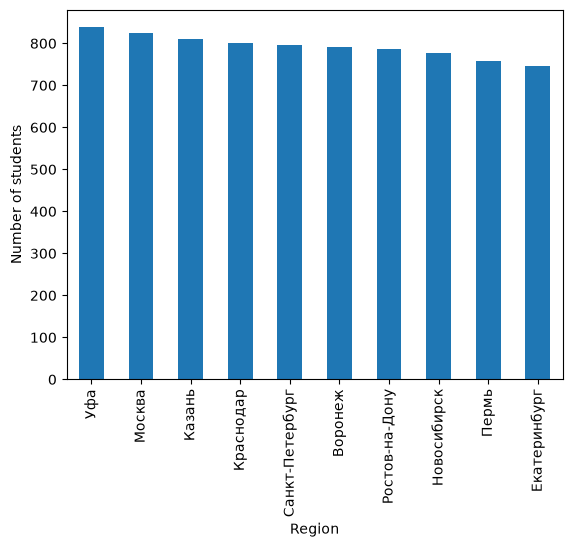

In [92]:
region_counts = df_valid["region"].value_counts()
print(region_counts)

region_counts.plot(kind="bar")
plt.xlabel("Region")
plt.ylabel("Number of students")
plt.show()

### Distribution of participants by region and grades

- The olympiad included **grades 5-11**, with numbers of students between **1093 to 1160**, so it was fairly distributed between grades.
- The olympiad included **10 regions**, with numbers of students between **745 and 838**, so number of students was also fairly distributed between regions.

count    590.000000
mean      13.437288
std        3.750988
min        4.000000
25%       11.000000
50%       13.000000
75%       16.000000
max       29.000000
dtype: float64


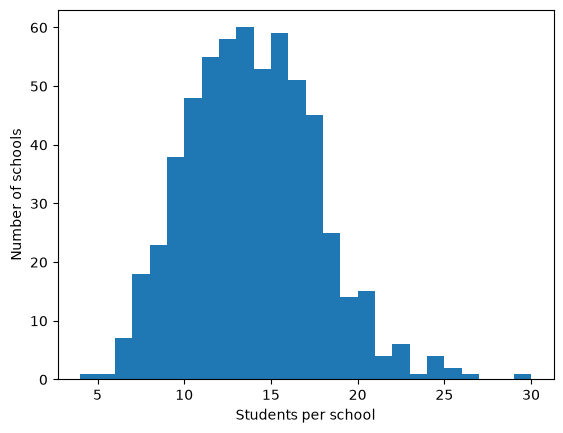

In [93]:
school_counts = df_valid.groupby(["region", "school_number"]).size()
print(school_counts.describe())

school_counts.plot(kind="hist", bins=range(4, 31))
plt.xlabel("Students per school")
plt.ylabel("Number of schools")
plt.show()

### Distribution of participants by school

- The olympiad included **590 schools**, with **13.4 students per school** on average (median 13).
- Half of the schools had **between 11 and 16 participants**, so most schools took part on a similar scale.
- School size ranged from **4 to 29 participants**, and few schools had more than 20.
- **88 schools (15%) had fewer than 10 participants**. Their averages are less reliable, so the top school rankings include only schools with at least 10 participants.

# Average score by grade

grade
5     4.50
6     4.85
7     5.26
8     5.46
9     5.91
10    6.21
11    6.62
Name: total_score, dtype: float64


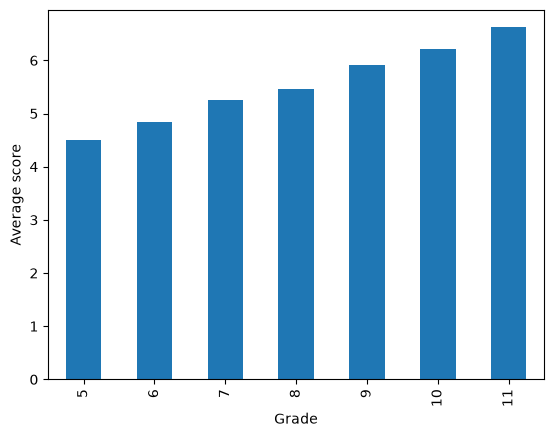

In [95]:
avg_score_by_grade = df_valid.groupby('grade')['total_score'].mean().round(2)
print(avg_score_by_grade)

avg_score_by_grade.plot(kind="bar")
plt.xlabel("Grade")
plt.ylabel("Average score")
plt.show()

- **Grade 11** have higher average score of **6.62** in comparison to other grades, which indicate that they might have studied more or the difficulty of exam was mostly for higher grades.

# Average score by region and by grade

In [96]:
pivot = df_valid.pivot_table(index="region", columns="grade", values="total_score", aggfunc="mean")
display(pivot.round(1))

grade,5,6,7,8,9,10,11
region,,,,,,,
Воронеж,4.2,5.0,5.4,5.6,5.8,6.2,6.6
Екатеринбург,5.4,4.7,4.9,5.2,6.3,5.9,6.9
Казань,4.3,4.7,5.1,5.5,6.0,6.4,6.6
Краснодар,4.3,4.7,5.2,5.3,5.7,6.1,6.3
Москва,4.8,5.0,5.2,5.8,6.1,6.3,6.5
Новосибирск,4.4,5.3,5.5,5.5,6.0,6.3,6.8
Пермь,4.5,4.9,4.8,5.6,5.7,5.9,6.4
Ростов-на-Дону,4.3,4.7,5.6,5.4,5.6,6.3,7.0
Санкт-Петербург,4.3,4.9,5.6,5.5,5.9,6.3,6.4


In [108]:
region_avg = df_valid.groupby("region")["total_score"].mean().round(2)
print(region_avg.sort_values(ascending=False))

region
Новосибирск        5.73
Москва             5.66
Екатеринбург       5.62
Ростов-на-Дону     5.60
Санкт-Петербург    5.58
Воронеж            5.50
Уфа                5.49
Казань             5.48
Краснодар          5.43
Пермь              5.38
Name: total_score, dtype: float64


# Device metrics

In [97]:
print(df_valid["device_type"].value_counts(normalize=True).mul(100).round(1))
display(df_valid.groupby("device_type")[["total_score", "tasks_answered", "disconnects"]].mean().round(2))

device_type
desktop    59.4
mobile     35.5
tablet      5.1
Name: proportion, dtype: float64


,total_score,tasks_answered,disconnects
device_type,,,
desktop,5.53,11.52,0.19
mobile,5.57,11.53,0.20
tablet,5.60,11.54,0.20


- High percentage of students used desktop **59.4%**, however this did not affect the average total score ranging from **5.53 for desktop**, to 5.60 for tablet, that means the type of device **did not affect** the score of student.

# Report for each region

In [ ]:
def region_report(region):
    data = df_valid[df_valid["region"] == region]

    print("Region:", region)
    print("Students:", len(data))
    print("Schools:", data["school_number"].nunique())
    print("Average score:", round(data["total_score"].mean(), 2))
    print("Overall average:", round(df_valid["total_score"].mean(), 2))

    print("Top schools:")
    display(get_top_schools(region))

    data["grade"].value_counts().sort_index().plot(kind="bar")
    plt.title("Students by grade: " + region)
    plt.xlabel("Grade")
    plt.ylabel("Students")
    plt.show()

    data.groupby("grade")["total_score"].mean().plot(kind="bar")
    plt.title("Average score by grade: " + region)
    plt.xlabel("Grade")
    plt.ylabel("Average score")
    plt.show()

Region: Воронеж
Students: 792
Schools: 59
Average score: 5.5
Overall average: 5.55
Top schools:


,region,school_number,students,mean_score
45,Воронеж,46,10,7.100000
52,Воронеж,53,12,6.666667
39,Воронеж,40,17,6.588235
26,Воронеж,27,12,6.500000
31,Воронеж,32,17,6.470588


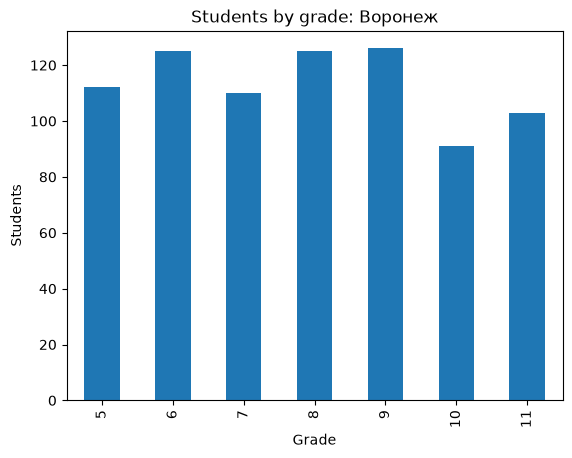

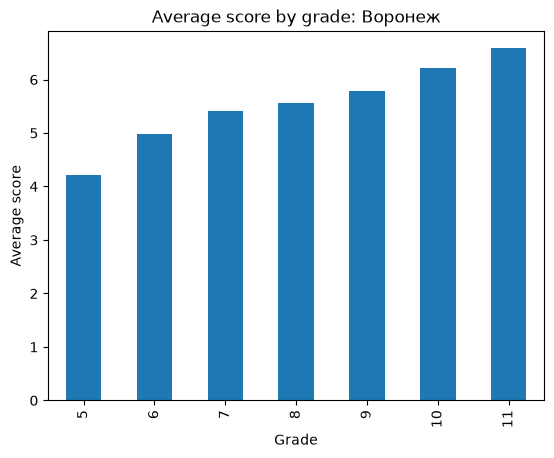

Region: Екатеринбург
Students: 745
Schools: 59
Average score: 5.62
Overall average: 5.55
Top schools:


,region,school_number,students,mean_score
80,Екатеринбург,22,10,7.100000
93,Екатеринбург,35,11,7.090909
105,Екатеринбург,47,18,6.611111
89,Екатеринбург,31,16,6.562500
84,Екатеринбург,26,10,6.500000


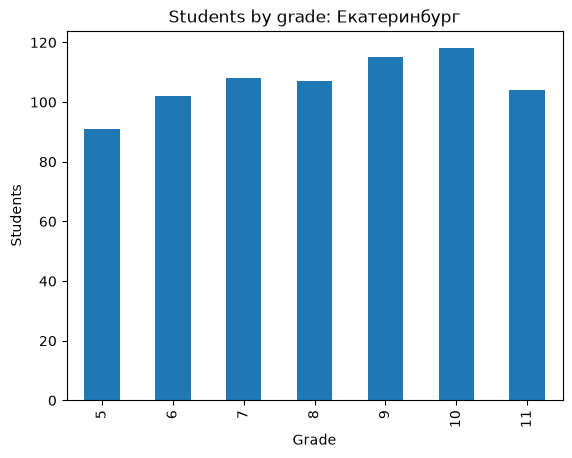

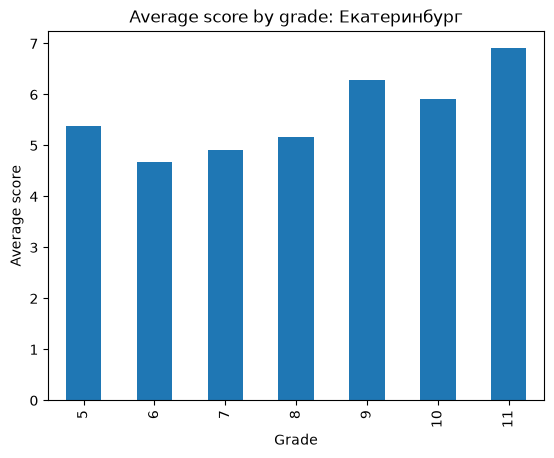

Region: Казань
Students: 811
Schools: 59
Average score: 5.48
Overall average: 5.55
Top schools:


,region,school_number,students,mean_score
122,Казань,5,21,7.285714
141,Казань,24,12,6.916667
128,Казань,11,10,6.800000
147,Казань,30,13,6.769231
126,Казань,9,15,6.733333


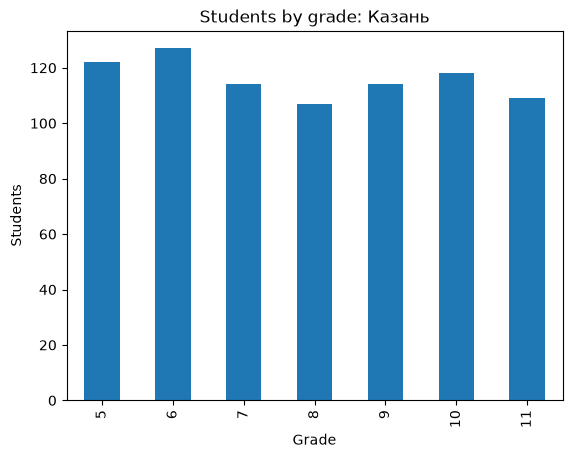

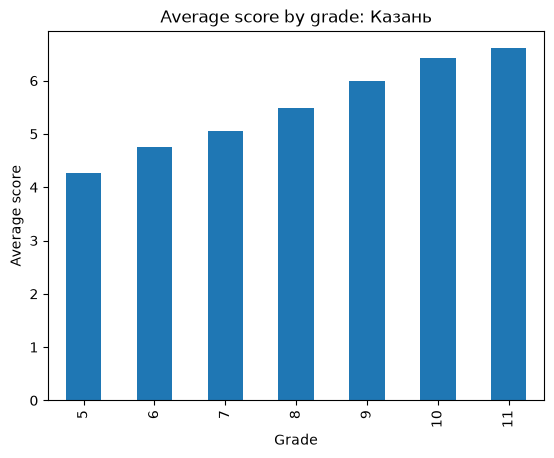

Region: Краснодар
Students: 801
Schools: 59
Average score: 5.43
Overall average: 5.55
Top schools:


,region,school_number,students,mean_score
229,Краснодар,53,12,7.166667
189,Краснодар,13,18,6.833333
182,Краснодар,6,17,6.764706
188,Краснодар,12,13,6.538462
225,Краснодар,49,15,6.466667


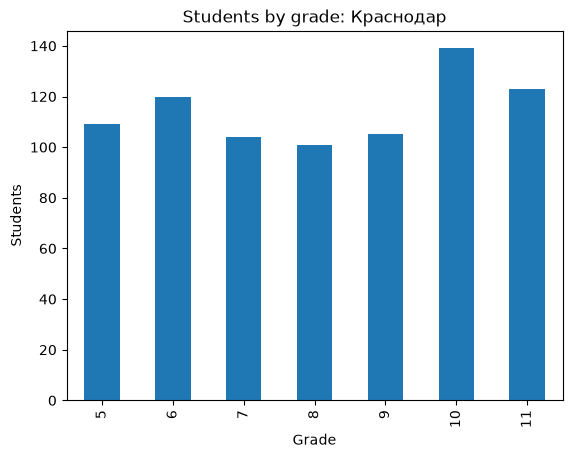

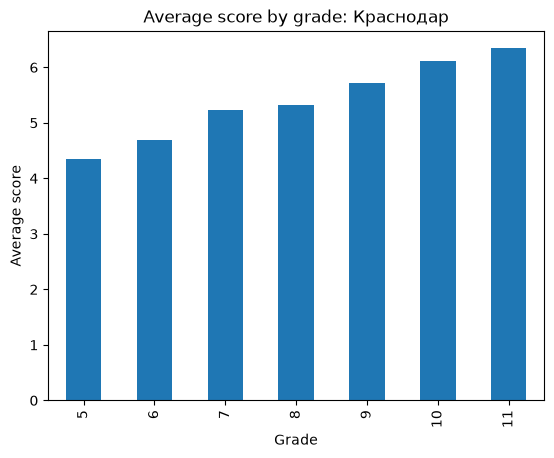

Region: Москва
Students: 824
Schools: 59
Average score: 5.66
Overall average: 5.55
Top schools:


,region,school_number,students,mean_score
261,Москва,26,10,7.500000
239,Москва,4,14,7.357143
278,Москва,43,12,6.833333
269,Москва,34,19,6.789474
263,Москва,28,16,6.750000


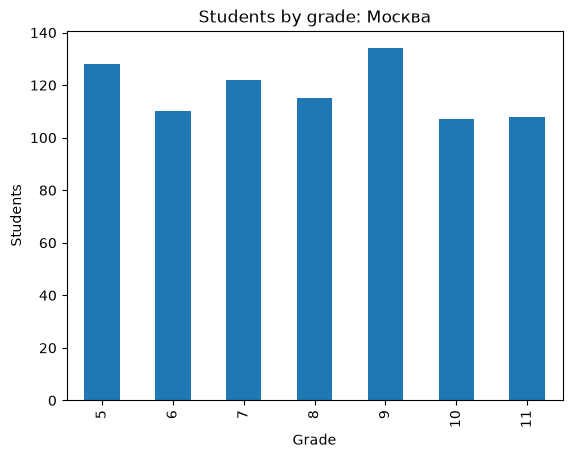

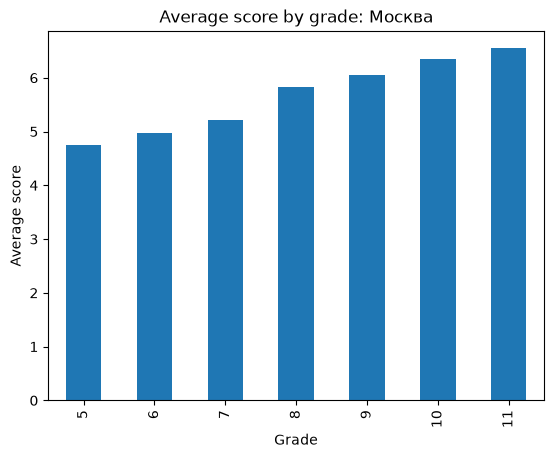

Region: Новосибирск
Students: 777
Schools: 59
Average score: 5.73
Overall average: 5.55
Top schools:


,region,school_number,students,mean_score
346,Новосибирск,52,10,7.500000
300,Новосибирск,6,12,7.250000
351,Новосибирск,57,12,7.166667
333,Новосибирск,39,17,7.117647
343,Новосибирск,49,12,6.666667


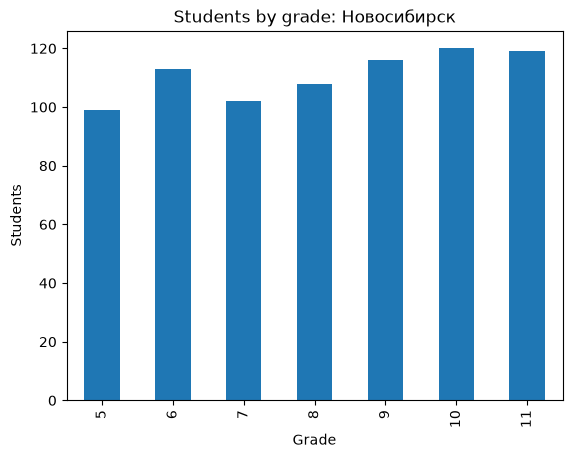

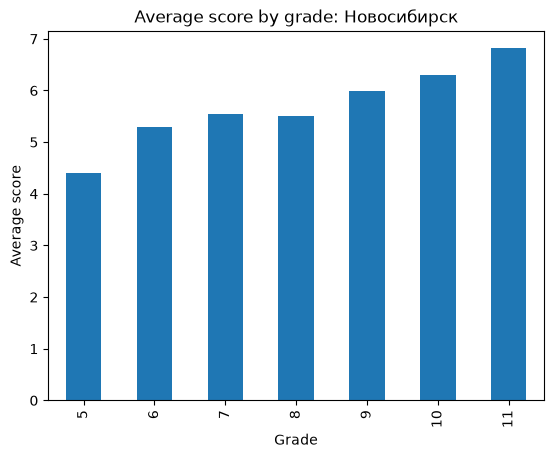

Region: Пермь
Students: 757
Schools: 59
Average score: 5.38
Overall average: 5.55
Top schools:


,region,school_number,students,mean_score
401,Пермь,48,14,7.285714
381,Пермь,28,11,6.909091
390,Пермь,37,10,6.700000
402,Пермь,49,12,6.666667
387,Пермь,34,17,6.411765


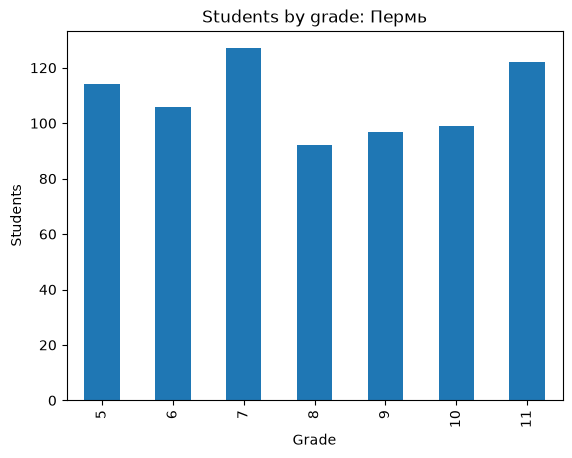

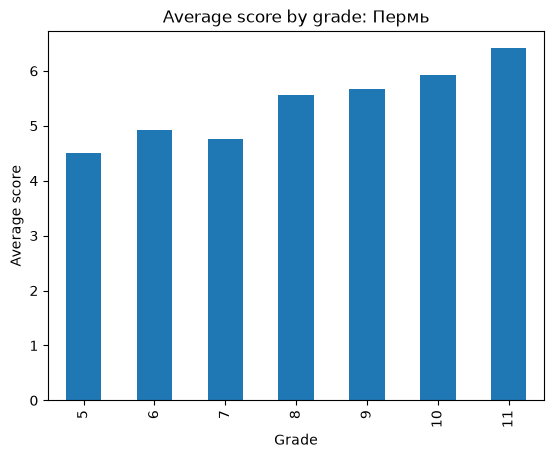

Region: Ростов-на-Дону
Students: 787
Schools: 59
Average score: 5.6
Overall average: 5.55
Top schools:


,region,school_number,students,mean_score
425,Ростов-на-Дону,13,20,7.950000
416,Ростов-на-Дону,4,13,7.769231
457,Ростов-на-Дону,45,14,7.142857
449,Ростов-на-Дону,37,15,6.733333
434,Ростов-на-Дону,22,15,6.600000


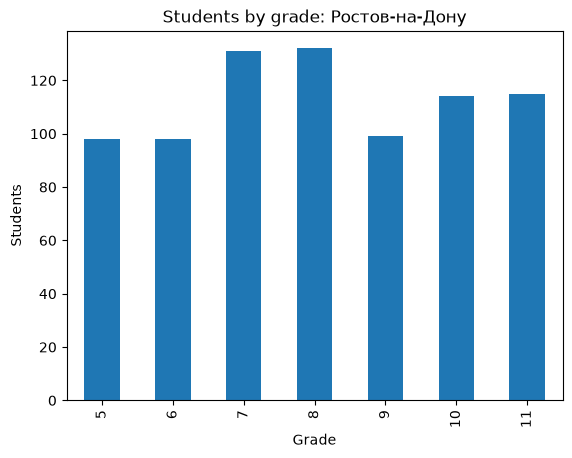

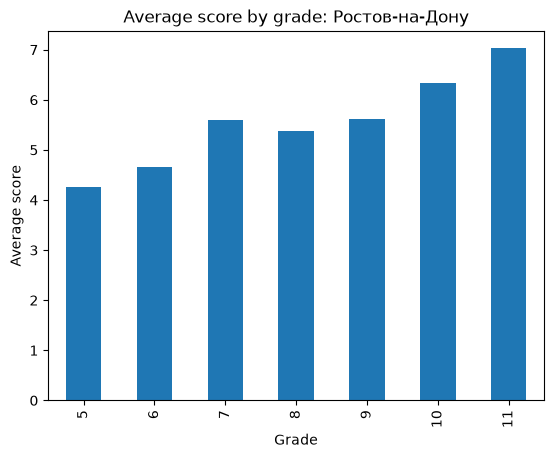

Region: Санкт-Петербург
Students: 796
Schools: 59
Average score: 5.58
Overall average: 5.55
Top schools:


,region,school_number,students,mean_score
482,Санкт-Петербург,11,12,7.916667
527,Санкт-Петербург,56,10,7.400000
511,Санкт-Петербург,40,21,7.190476
484,Санкт-Петербург,13,11,6.727273
522,Санкт-Петербург,51,12,6.666667


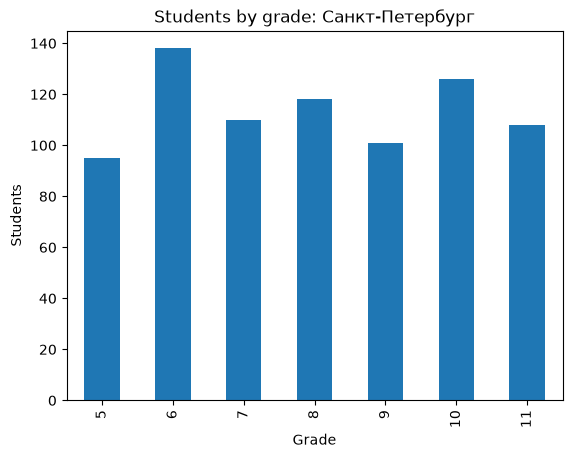

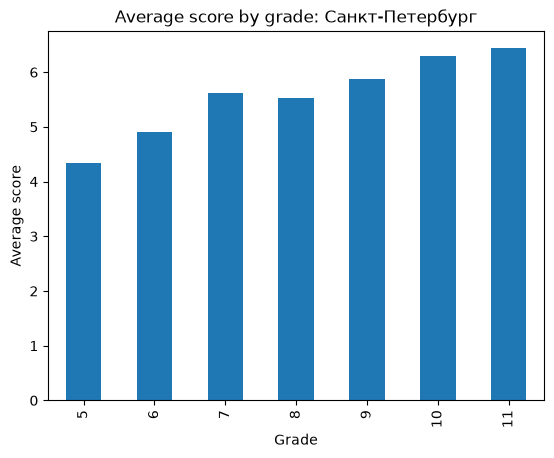

Region: Уфа
Students: 838
Schools: 59
Average score: 5.49
Overall average: 5.55
Top schools:


,region,school_number,students,mean_score
587,Уфа,57,11,7.000000
582,Уфа,52,15,6.866667
583,Уфа,53,16,6.562500
562,Уфа,32,15,6.533333
559,Уфа,29,12,6.500000


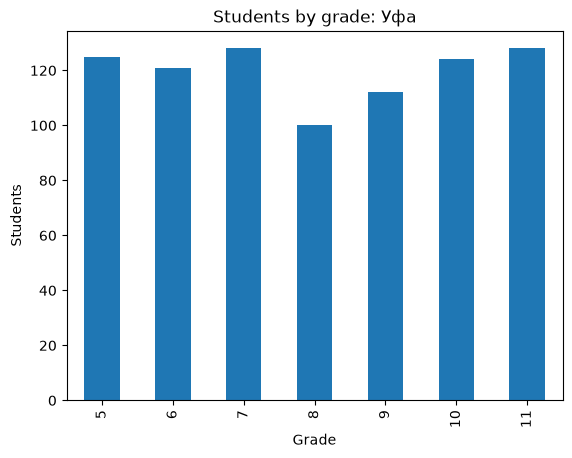

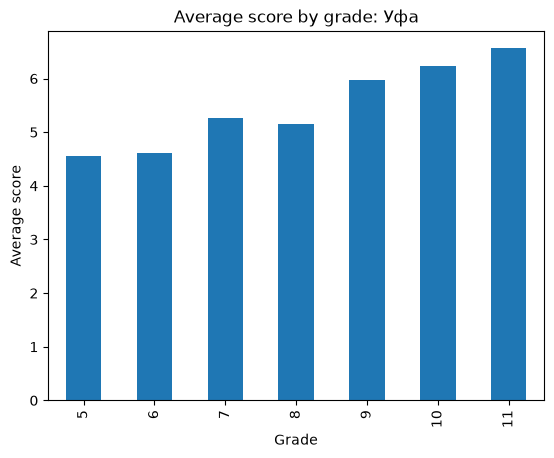

In [ ]:
for region in sorted(df_valid["region"].unique()):
    region_report(region)

### Main findings

- The olympiad reached a balanced audience across grades, regions and devices. **Grade explains scores far better than region or device.** The main opportunity is reviewing the four hardest tasks and whether one test suits grades 5 to 11.
- Regional averages range only from **5.38 (Perm) to 5.73 (Novosibirsk)**. These gaps are too small to treat as a firm ranking of regions.
- Average scores rise with grade in every region, from about 4.2–5.4 in grade 5 to about 6.3–7.0 in grade 11
- The results suggest that tasks 1,2,3 and 9 were the hardest taks with solving rate of only 29.8% - 37.8, in comparison with task 5 which seems to be the easiet task in the competition with solving rate of 63.9% 

### Recommendations
- **Education team:** review Tasks 1, 2, 3 and 9 to see whether they are too hard or unclear.
- **Education team:** consider separate tests or results by age group if all grades take one test.
- **Product team:** add an automatic check for sessions under 1 minute.
- **Product team:** keep supporting mobile devices, since about a third of students use them and their scores match desktop.